# Tracer flight recorder

Per-step latency by role, budget pressure over time, and tokens by role.

In [6]:
from collections import defaultdict

import matplotlib.pyplot as plt

from tracer import Tracer, new_step_id

In [7]:
# Sample run shaped like the city-report task (replace with tr = Tracer(); load real dump)
tr = Tracer()
plan_id = new_step_id()
tr.record(role="planner", action="plan", step_id=plan_id, latency_ms=800, tokens=350, cost=0.01, budget_pressure=0.05)
for city in ("Paris", "Berlin"):
    tr.record(role="worker", action="get_population", parent_id=plan_id, latency_ms=15, tokens=0, cost=0.0, budget_pressure=0.08)
    tr.record(role="worker", action="get_timezone", parent_id=plan_id, latency_ms=12, tokens=0, cost=0.0, budget_pressure=0.10)
    tr.record(role="worker", action="summarise_city", parent_id=plan_id, latency_ms=1400, tokens=420, cost=0.02, budget_pressure=0.35)
tr.record(role="worker", action="aggregate_report", parent_id=plan_id, latency_ms=2200, tokens=900, cost=0.05, budget_pressure=0.72)
tr.record(role="critic", action="verify_report", latency_ms=600, tokens=200, cost=0.01, budget_pressure=0.78, verdict="pass")
ev = tr.dump()
ev

[{'step_id': 'bd4907b5e221',
  'parent_id': None,
  'role': 'planner',
  'action': 'plan',
  'latency_ms': 800,
  'tokens': 350,
  'cost': 0.01,
  'budget_pressure': 0.05,
  't': 0.000435416994150728},
 {'step_id': '1cfd4bdf6df5',
  'parent_id': 'bd4907b5e221',
  'role': 'worker',
  'action': 'get_population',
  'latency_ms': 15,
  'tokens': 0,
  'cost': 0.0,
  'budget_pressure': 0.08,
  't': 0.0005460419924929738},
 {'step_id': '42e7471cbe64',
  'parent_id': 'bd4907b5e221',
  'role': 'worker',
  'action': 'get_timezone',
  'latency_ms': 12,
  'tokens': 0,
  'cost': 0.0,
  'budget_pressure': 0.1,
  't': 0.0005647090147249401},
 {'step_id': '7b32d631f1c1',
  'parent_id': 'bd4907b5e221',
  'role': 'worker',
  'action': 'summarise_city',
  'latency_ms': 1400,
  'tokens': 420,
  'cost': 0.02,
  'budget_pressure': 0.35,
  't': 0.0005695000290870667},
 {'step_id': 'aafd3c390fb8',
  'parent_id': 'bd4907b5e221',
  'role': 'worker',
  'action': 'get_population',
  'latency_ms': 15,
  'tokens': 

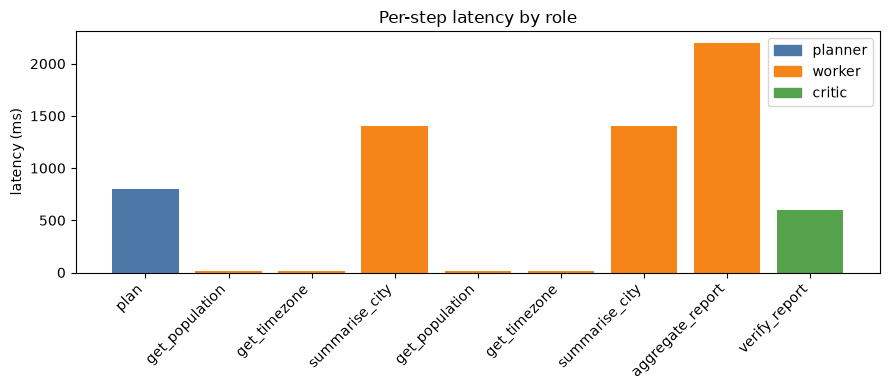

In [8]:
# Per-step latency, colored by role
role_colors = {"planner": "#4C78A8", "worker": "#F58518", "critic": "#54A24B"}
fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(ev))
colors = [role_colors.get(e["role"], "#999999") for e in ev]
ax.bar(x, [e["latency_ms"] for e in ev], color=colors)
ax.set_xticks(list(x))
ax.set_xticklabels([e["action"] for e in ev], rotation=45, ha="right")
ax.set_ylabel("latency (ms)")
ax.set_title("Per-step latency by role")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in role_colors.values()]
ax.legend(handles, role_colors.keys())
fig.tight_layout()
plt.show()

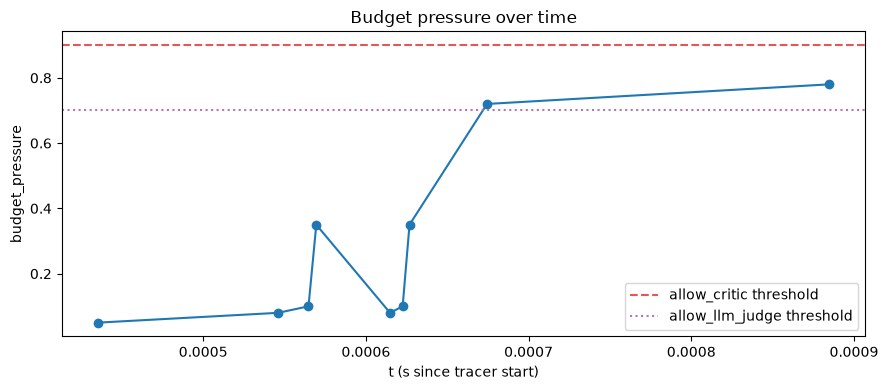

In [9]:
# Budget pressure over time
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot([e["t"] for e in ev], [e["budget_pressure"] for e in ev], marker="o")
ax.axhline(0.9, linestyle="--", color="#E45756", label="allow_critic threshold")
ax.axhline(0.7, linestyle=":", color="#B279A2", label="allow_llm_judge threshold")
ax.set_xlabel("t (s since tracer start)")
ax.set_ylabel("budget_pressure")
ax.set_title("Budget pressure over time")
ax.legend()
fig.tight_layout()
plt.show()

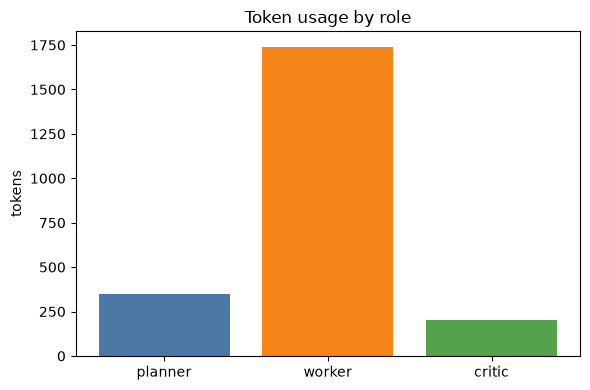

{'planner': 350, 'worker': 1740, 'critic': 200}

In [10]:
# Tokens by role
by_role = defaultdict(int)
for e in ev:
    by_role[e["role"]] += e["tokens"]

fig, ax = plt.subplots(figsize=(6, 4))
roles = list(by_role.keys())
ax.bar(roles, [by_role[r] for r in roles], color=[role_colors.get(r, "#999999") for r in roles])
ax.set_ylabel("tokens")
ax.set_title("Token usage by role")
fig.tight_layout()
plt.show()
dict(by_role)